In [2]:
pip  install  pandas  openpyxl

Note: you may need to restart the kernel to use updated packages.


In [6]:
import pandas as pd

file_path = r"C:\Users\yseda\Downloads\G20 ANALİZİ.xlsx"
veri = pd.read_excel(file_path)
print(veri.head())

    Yıl        Ulke      Nufus  Yuzolcumu  CO2_Emisyonu  Kisi_Basina_Gelir  \
0  2015     Almanya   81589465     349360        785400              41911   
1  2015         ABD  324628169    9147420       5133200              57040   
2  2015    Arjantin   43252203    2736690        196300              13679   
3  2015  Avustralya   23768258    7692020        400500              56739   
4  2015    Brezilya  200891199    8358140        517600               8936   

   Enflasyon_Orani  Sanayi_Endeksi  Internet_Kullanici_Orani  \
0              0.5             0.9                        88   
1              0.1             2.8                        75   
2             26.9            -2.7                        68   
3              1.5             0.7                        85   
4              9.0            -4.9                        58   

   Yillik_Ortalama_Sicaklik  Okuryazarlik_Orani Ekonomik_Kategori  \
0                     10.31                  99          Gelismis   
1       

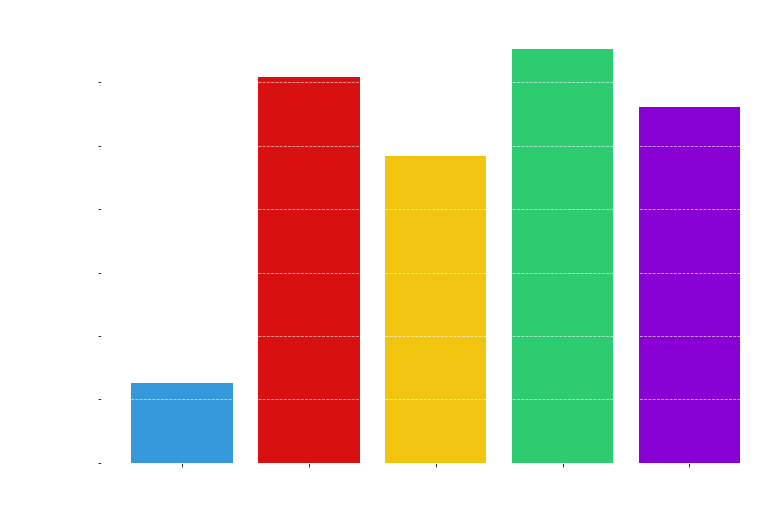

In [9]:
import matplotlib.pyplot as plt
regional_gdp = veri.groupby("Bolge")["Kisi_Basina_Gelir"].mean().reset_index()


plt.figure(figsize=(12, 8))
plt.bar(regional_gdp["Bolge"], regional_gdp["Kisi_Basina_Gelir"], 
        color=["#3498db", "#d91010", "#f1c40f", "#2ecc71", "#8900D5"])  

plt.xlabel("Bölge", fontsize=20, color="white", fontweight="bold")
plt.ylabel("Ortalama Kişi Başına Gelir ($)", fontsize=20, color="white", fontweight="bold")
plt.title("G20 Bölgelerinin Ortalama Kişi Başına Gelir Karşılaştırması", fontsize=20, color="white", fontweight="bold")

plt.xticks(rotation=0, fontsize=18, color="white")
plt.yticks(fontsize=20, color="white")

plt.gca().spines["top"].set_color("white")
plt.gca().spines["bottom"].set_color("white")
plt.gca().spines["left"].set_color("white")
plt.gca().spines["right"].set_color("white")

plt.gca().set_facecolor("white")
plt.grid(axis="y", linestyle="--", alpha=0.7, color="white")
plt.savefig(r"C:\Users\yseda\Documents\grafik_seffaf.png", transparent=True, dpi=300)
plt.show()

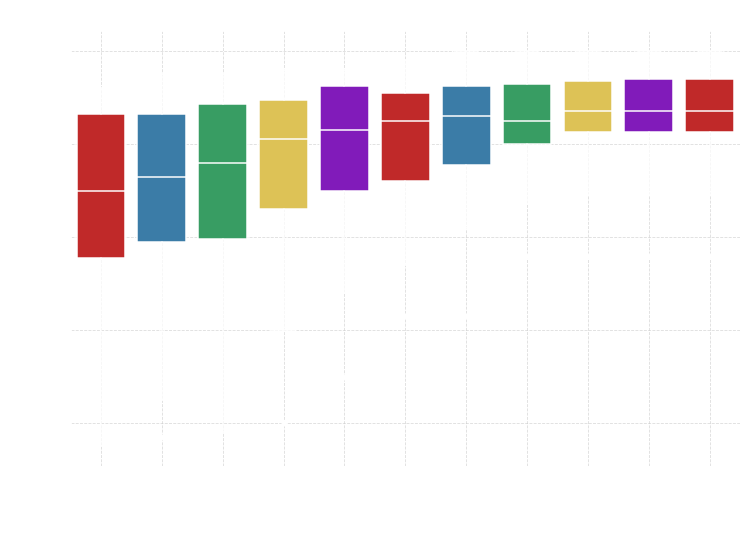

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt


sns.set_style("whitegrid")
fig, ax = plt.subplots(figsize=(12, 8))

sns.boxplot(
    x='Yıl', y='Internet_Kullanici_Orani', data=veri, 
    ax=ax, palette=["#d91010", "#2980B9", "#27AE60", "#F4D03F", "#8900D5"], 
    boxprops={'edgecolor': 'white'},  
    whiskerprops={'color': 'white'},  
    capprops={'color': 'white'},  
    medianprops={'color': 'white'},  
    flierprops={'marker': 'o', 'markerfacecolor': 'white', 'markeredgecolor': 'white'} 
)

ax.set_title('Yıllara Göre İnternet Kullanıcı Oranı Dağılımı', fontsize=20, color="white", fontweight="bold")
ax.set_xlabel('Yıl', fontsize=20, color="white", fontweight="bold")
ax.set_ylabel('İnternet Kullanıcı Oranı (%)', fontsize=20, color="white", fontweight="bold")
ax.tick_params(axis='x', colors="white", labelsize=18) 
ax.tick_params(axis='y', colors="white", labelsize=18)
ax.spines["top"].set_color("white")
ax.spines["bottom"].set_color("white")
ax.spines["left"].set_color("white")
ax.spines["right"].set_color("white")

fig.patch.set_facecolor("white")
ax.set_facecolor("white")

plt.xticks(rotation=45, fontsize=16)  
plt.grid(True, linestyle="--", alpha=0.7)
plt.savefig(r"C:\Users\yseda\Documents\grafik_seffaf.png", transparent=True, dpi=300)
plt.show()

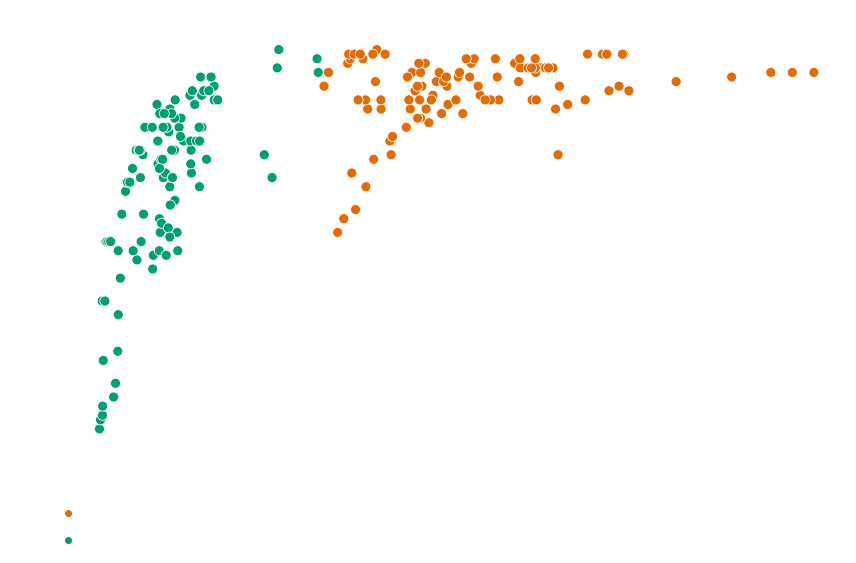

In [11]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


veri_filtered = veri[(veri['Kisi_Basina_Gelir'] < 100_000) & 
                 (veri['Internet_Kullanici_Orani'] < 100)]
plt.figure(figsize=(12, 8))

custom_palette = {
    "Gelismekte Olan": "#009E73", 
    "Gelismis": "#E56B00"  
}

sns.scatterplot(
    data=veri_filtered,
    x='Kisi_Basina_Gelir',
    y='Internet_Kullanici_Orani',
    hue='Ekonomik_Kategori',
    palette=custom_palette,  
    s=100,
    alpha= 1
)

plt.xlabel("Kişi Başına Gelir (USD)", fontsize=20, fontweight="bold", color="#FFFFFF")  
plt.ylabel("İnternet Kullanıcı Oranı (%)", fontsize=20, fontweight="bold", color="#FFFFFF")  
plt.title("Kişi Başına Gelir ile İnternet Kullanımı Arasındaki İlişki", fontsize=20, fontweight="bold", color="#FFFFFF") 


plt.grid(linestyle="--", alpha=0.7, color="#FFFFFF", linewidth=1.2)
plt.xticks(fontsize=14, fontweight="bold", color="#FFFFFF") 
plt.yticks(fontsize=14, fontweight="bold", color="#FFFFFF")  


plt.gca().spines["bottom"].set_color("#FFFFFF")
plt.gca().spines["left"].set_color("#FFFFFF")
plt.gca().spines["top"].set_color("#FFFFFF")
plt.gca().spines["right"].set_color("#FFFFFF")

plt.gca().spines["bottom"].set_linewidth(1.5) 
plt.gca().spines["left"].set_linewidth(1.5)
plt.gca().spines["top"].set_linewidth(1.5)
plt.gca().spines["right"].set_linewidth(1.5)


legend = plt.legend(title="Ekonomik Kategori", fontsize=18, frameon=False, loc="lower center", bbox_to_anchor=(0.1, -0.28))
plt.setp(legend.get_texts(), color="#FFFFFF")  
plt.setp(legend.get_title(), color="#FFFFFF", fontsize=20) 

plt.tight_layout()
plt.savefig("C:\\Users\\yseda\\Desktop\\sacilim.png", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

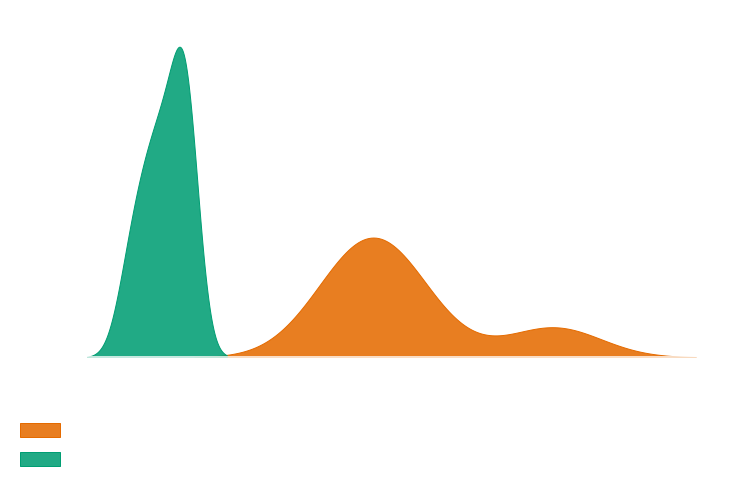

In [12]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt


veri_turkiye = veri[veri["Ulke"] == "Turkiye"]
veri_avrupa = veri[(veri["Ulke"] != "Turkiye") & (veri["Bolge"] == "Avrupa")]

veri_avrupa_avg = veri_avrupa.groupby("Yıl")["Yillik_Ortalama_Sicaklik"].mean().reset_index()
veri_avrupa_avg["Ulke"] = "Avrupa Ortalama"

plt.figure(figsize=(12, 6))

sns.kdeplot(
    data=veri_turkiye,
    x="Yillik_Ortalama_Sicaklik",
    color="#E56B00",  
    fill=True,
    alpha=0.87,
    label="Türkiye"
)

sns.kdeplot(
    data=veri_avrupa_avg,
    x="Yillik_Ortalama_Sicaklik",
    color="#009E73", 
    fill=True,
    alpha=0.87,
    label="Avrupa Ortalama"
)

plt.xlabel("Yıllık Ortalama Sıcaklık (°C)", fontsize=20, fontweight="bold", color="#FFFFFF")
plt.ylabel("Yoğunluk", fontsize=20, fontweight="bold", color="#FFFFFF")
plt.title("Türkiye ve Avrupa Ülkelerinin Ortalama Sıcaklık Dağılımı", fontsize=20, fontweight="bold", color="#FFFFFF")

plt.grid(linestyle="--", alpha=0.7, color="#FFFFFF", linewidth=1.2)
plt.xticks(fontsize=14, fontweight="bold", color="#FFFFFF")
plt.yticks(fontsize=14, fontweight="bold", color="#FFFFFF")

plt.gca().spines["bottom"].set_color("#FFFFFF")
plt.gca().spines["left"].set_color("#FFFFFF")
plt.gca().spines["top"].set_color("#FFFFFF")
plt.gca().spines["right"].set_color("#FFFFFF")

plt.gca().spines["bottom"].set_linewidth(1.5)
plt.gca().spines["left"].set_linewidth(1.5)
plt.gca().spines["top"].set_linewidth(1.5)
plt.gca().spines["right"].set_linewidth(1.5)


legend = plt.legend(title="Bölge", fontsize=20, frameon=False, loc="lower center", bbox_to_anchor=(0.1, -0.4))
plt.setp(legend.get_texts(), color="#FFFFFF", fontsize=20)  
plt.setp(legend.get_title(), color="#FFFFFF", fontsize=20)
plt.savefig("C:\\Users\\yseda\\Desktop\\sicaklik_avrupa_yogunluk.png", dpi=300, bbox_inches="tight", transparent=True)
plt.show()

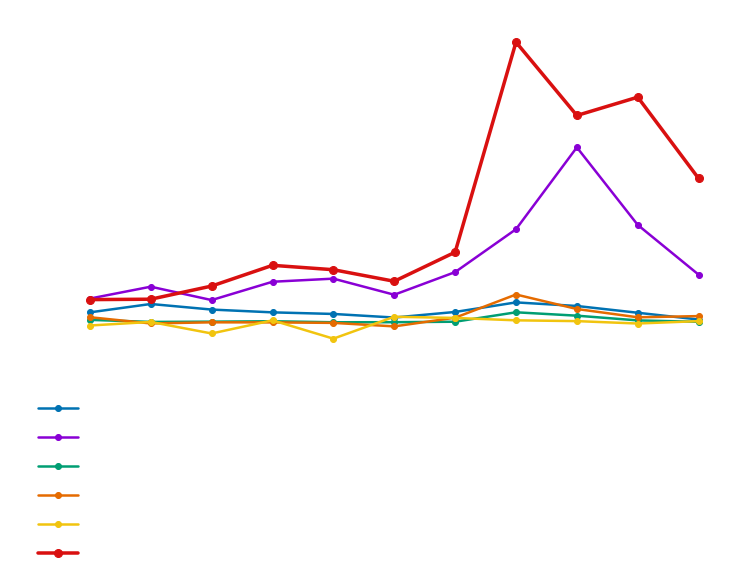

In [13]:
import pandas as pd
import matplotlib.pyplot as plt


veri.dropna(subset=["Yıl", "Enflasyon_Orani", "Bolge", "Ulke"], inplace=True)
veri_turkiye = veri[veri["Ulke"] == "Turkiye"]

regional_avg = veri[veri["Ulke"] != "Turkiye"].groupby(["Yıl", "Bolge"])["Enflasyon_Orani"].mean().reset_index()
plt.figure(figsize=(12, 6))

colors = {
    "Avrupa": "#E56B00",
    "Asya - Pasifik": "#009E73",
    "Amerika": "#8900D5",
    "Orta Doğu": "#F1C40F",
    "Afrika": "#0072B2",
    "Turkiye": "#d91010" 
}


for region in regional_avg["Bolge"].unique():
    if region in colors:  
        plt.plot(
            regional_avg[regional_avg["Bolge"] == region]["Yıl"],
            regional_avg[regional_avg["Bolge"] == region]["Enflasyon_Orani"],
            label=region,
            color=colors[region],
            linewidth=2.5,
            marker="o"
        )

plt.plot(
    veri_turkiye["Yıl"],
    veri_turkiye["Enflasyon_Orani"],
    label="Türkiye",
    color=colors["Turkiye"],
    linewidth=3.5,  
    linestyle="-",  
    marker="o",
    markersize=8  
)
plt.xlabel("Yıl", fontsize=20, fontweight="bold", color="#FFFFFF")
plt.ylabel("Ortalama Enflasyon Oranı (%)", fontsize=20, fontweight="bold", color="#FFFFFF")
plt.title("G20 Bölgeleri ve Türkiye - Yıllık Ortalama Enflasyon Oranı Trendleri", fontsize=20, fontweight="bold", color="#FFFFFF")


plt.grid(linestyle="--", alpha=0.7, color="#FFFFFF", linewidth=1.2)
plt.xticks(fontsize=20, color="#FFFFFF")
plt.yticks(fontsize=20, color="#FFFFFF")


plt.gca().spines["bottom"].set_color("#FFFFFF")
plt.gca().spines["left"].set_color("#FFFFFF")
plt.gca().spines["top"].set_color("#FFFFFF")
plt.gca().spines["right"].set_color("#FFFFFF")

plt.gca().spines["bottom"].set_linewidth(1.5)
plt.gca().spines["left"].set_linewidth(1.5)
plt.gca().spines["top"].set_linewidth(1.5)
plt.gca().spines["right"].set_linewidth(1.5)


plt.legend(loc="lower center", bbox_to_anchor=(0.1, -0.7), frameon=False, fontsize=20, labelcolor="#FFFFFF")
plt.savefig("C:\\Users\\yseda\\Desktop\\g20_enflasyon_trendi_turkiye.png", dpi=300, bbox_inches="tight", transparent=True)
plt.show()